In [1]:
from pathlib import Path
import torch

from configs.swin3d_small import TRAIN_CONFIG
from datasets.belize_laz_dataset import create_dataloaders
from models.swin3d_model import Model

from visualization.vis import (
    visualize_tile,
    visualize_prediction_errors,
    find_archaeological_tiles,
    print_archaeological_tiles,

    evaluate_test_tiles,
    find_extreme_test_tiles,
    print_extreme_test_tiles,
)

/path/to/envs/maya_env/lib/python3.10/site-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla V100-PCIE-16GB


In [3]:
train_loader, validation_loader, test_loader = create_dataloaders(
    split_dir="dataset_splits",
    batch_size=TRAIN_CONFIG["batch_size"],
    voxel_max=TRAIN_CONFIG["voxel_max"],
    num_workers=4,
    augmentation_ratio=TRAIN_CONFIG["augmentation_ratio"],
)

print("Test tiles:", len(test_loader.dataset))
print("Test batches:", len(test_loader))

Test tiles: 80
Test batches: 5


In [4]:
model = Model(
    num_classes=TRAIN_CONFIG["num_classes"],
    in_channels=4,
).to(device)

print("Model created.")

Model created.


In [5]:
BEST_CHECKPOINT = Path(
    "/path/to/project_storage/"
    "swin3d_checkpoints/"
    "dice_vicinity/"
    "swin3d_dice_vicinity_best_02.pth"
)

print("Checkpoint exists:", BEST_CHECKPOINT.exists())
print("Checkpoint:", BEST_CHECKPOINT)

Checkpoint exists: True
Checkpoint: /path/to/project_storage/swin3d_checkpoints/dice_vicinity/swin3d_dice_vicinity_best_02.pth


In [6]:
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

/tmp/ipykernel_498079/2326245694.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


Checkpoint epoch: 55


In [7]:
archaeological_tiles = find_archaeological_tiles(
    dataset=test_loader.dataset,
    minimum_archaeology_points=100,
    sort_by="archaeology",
)

print_archaeological_tiles(
    archaeological_tiles,
    limit=20,
)

Archaeological tiles found: 76

 Index   Structure    Plazuela  Total Arch  File
------------------------------------------------------------------------------------------
    71           0      19,475      19,475  tile_redacted_0009.laz
    61      14,569         133      14,702  tile_redacted_0010.laz
     9           0      14,655      14,655  tile_redacted_0011.laz
    28           0      11,965      11,965  tile_redacted_0012.laz
    49       2,042       9,364      11,406  tile_redacted_0013.laz
    27       3,441       7,952      11,393  tile_redacted_0014.laz
     3           0       9,425       9,425  tile_redacted_0015.laz
     0         972       7,653       8,625  tile_redacted_0016.laz
    53         526       7,744       8,270  tile_redacted_0017.laz
    14         806       7,255       8,061  tile_redacted_0018.laz
    76       1,539       6,478       8,017  tile_redacted_0019.laz
    78           0       7,790       7,790  tile_redacted_0020.laz
    11         839      

In [8]:
tile_index = archaeological_tiles[0]["index"] if archaeological_tiles else 0
print("Selected tile:", tile_index)

Selected tile: 71


In [9]:
tile_index = 9

/path/to/envs/maya_env/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/path/to/software/Swin3D/Swin3D/modules/swin3d_layers.py:239: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at ../torch/csrc/tensor/python_tensor.cpp:78.)
  offset = torch.cuda.IntTensor(offset)


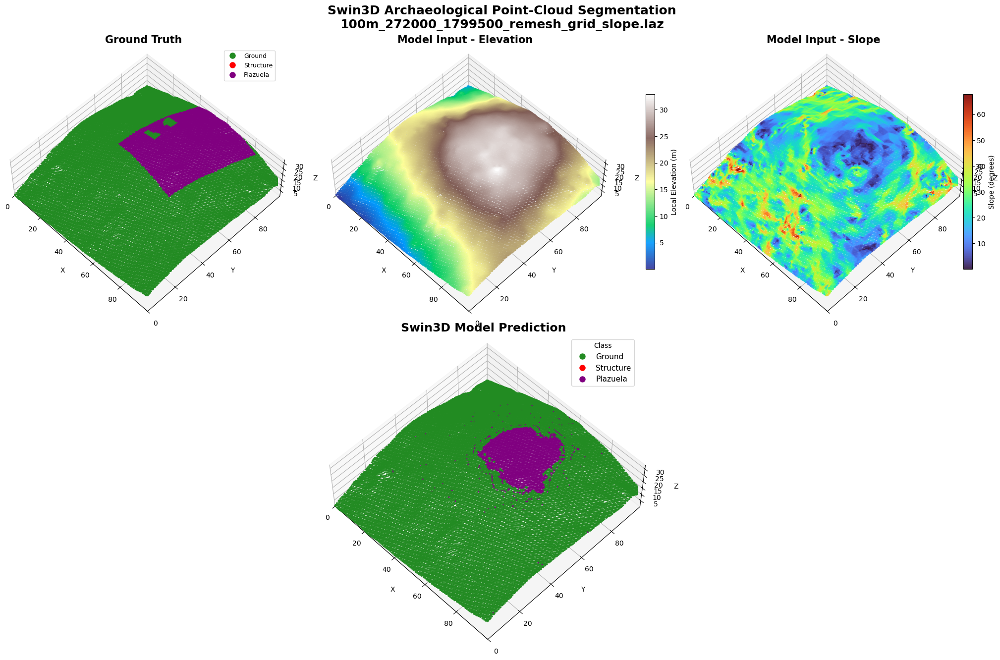


Tile: tile_redacted_0011.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     50,345
  Structure :          0
  Plazuela  :     14,655

Prediction counts:
  Ground    :     58,804
  Structure :          0
  Plazuela  :      6,196

Point accuracy: 0.8633


In [10]:
visualization_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=tile_index,
    device=device,
    max_plot_points=40000,
    point_size=1.5,
    elevation_angle=55,
    azimuth_angle=-45,
)

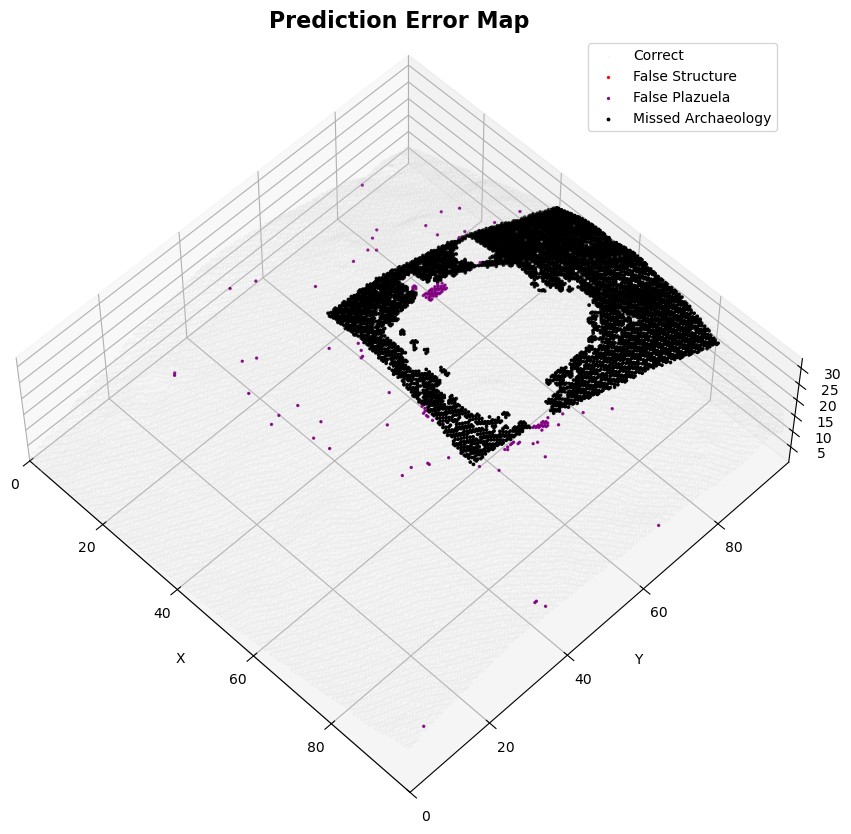

{'correct': 34528, 'false_structure': 0, 'false_plazuela': 137, 'missed_archaeology': 5335}


In [11]:
error_counts = visualize_prediction_errors(
    visualization_output,
    max_plot_points=40000,
    point_size=2.0,
    elevation_angle=55,
    azimuth_angle=-45,
)

print(error_counts)

In [12]:
tile_results = evaluate_test_tiles(
    model=model,
    dataset=test_loader.dataset,
    device=device,
    print_progress=True,
)

Evaluated tile 001/080
Evaluated tile 010/080
Evaluated tile 020/080
Evaluated tile 030/080
Evaluated tile 040/080
Evaluated tile 050/080
Evaluated tile 060/080
Evaluated tile 070/080
Evaluated tile 080/080


In [13]:
tile_results

[{'index': 0,
  'accuracy': 0.9303692307692307,
  'false_positive_count': 2063,
  'false_positive_rate': 0.036594235033259426,
  'structure_false_positives': 0,
  'plazuela_false_positives': 2063,
  'ground_points': 56375,
  'structure_gt': 972,
  'plazuela_gt': 7653,
  'path': '/path/to/authorized/training_laz/tile_redacted_0016.laz'},
 {'index': 1,
  'accuracy': 0.9558153846153846,
  'false_positive_count': 2807,
  'false_positive_rate': 0.043875142629382434,
  'structure_false_positives': 0,
  'plazuela_false_positives': 2807,
  'ground_points': 63977,
  'structure_gt': 54,
  'plazuela_gt': 969,
  'path': '/path/to/authorized/training_laz/tile_redacted_0029.laz'},
 {'index': 2,
  'accuracy': 0.9228,
  'false_positive_count': 2919,
  'false_positive_rate': 0.046833635503072506,
  'structure_false_positives': 0,
  'plazuela_false_positives': 2919,
  'ground_points': 62327,
  'structure_gt': 0,
  'plazuela_gt': 2673,
  'path': '/path/to/authorized/training_laz/tile_redacted_0030.laz'},

In [14]:
extreme_tiles = find_extreme_test_tiles(
    tile_results,
    top_k=5,
)

print_extreme_test_tiles(
    extreme_tiles
)


TOP HIGHEST ACCURACY

Rank 1
Tile index: 75
Path: /path/to/authorized/training_laz/tile_redacted_0086.laz
Accuracy: 0.9926
False-positive count: 470
False-positive rate: 0.0074
----------------------------------------------------------------------

Rank 2
Tile index: 7
Path: /path/to/authorized/training_laz/tile_redacted_0034.laz
Accuracy: 0.9880
False-positive count: 753
False-positive rate: 0.0117
----------------------------------------------------------------------

Rank 3
Tile index: 36
Path: /path/to/authorized/training_laz/tile_redacted_0056.laz
Accuracy: 0.9867
False-positive count: 542
False-positive rate: 0.0087
----------------------------------------------------------------------

Rank 4
Tile index: 64
Path: /path/to/authorized/training_laz/tile_redacted_0078.laz
Accuracy: 0.9854
False-positive count: 847
False-positive rate: 0.0132
----------------------------------------------------------------------

Rank 5
Tile index: 40
Path: /path/to/authorized/training_laz/tile_reda

In [15]:
extreme_tiles 

{'highest_accuracy': [{'index': 75,
   'accuracy': 0.9926307692307692,
   'false_positive_count': 470,
   'false_positive_rate': 0.007376367374484047,
   'structure_false_positives': 0,
   'plazuela_false_positives': 470,
   'ground_points': 63717,
   'structure_gt': 0,
   'plazuela_gt': 1283,
   'path': '/path/to/authorized/training_laz/tile_redacted_0086.laz'},
  {'index': 7,
   'accuracy': 0.9879846153846154,
   'false_positive_count': 753,
   'false_positive_rate': 0.011706361544680056,
   'structure_false_positives': 0,
   'plazuela_false_positives': 753,
   'ground_points': 64324,
   'structure_gt': 0,
   'plazuela_gt': 676,
   'path': '/path/to/authorized/training_laz/tile_redacted_0034.laz'},
  {'index': 36,
   'accuracy': 0.9866615384615385,
   'false_positive_count': 542,
   'false_positive_rate': 0.008690772067666159,
   'structure_false_positives': 0,
   'plazuela_false_positives': 542,
   'ground_points': 62365,
   'structure_gt': 0,
   'plazuela_gt': 2635,
   'path': '/pa


Highest Accuracy Tile #1
Tile index: 75
Accuracy: 0.9926


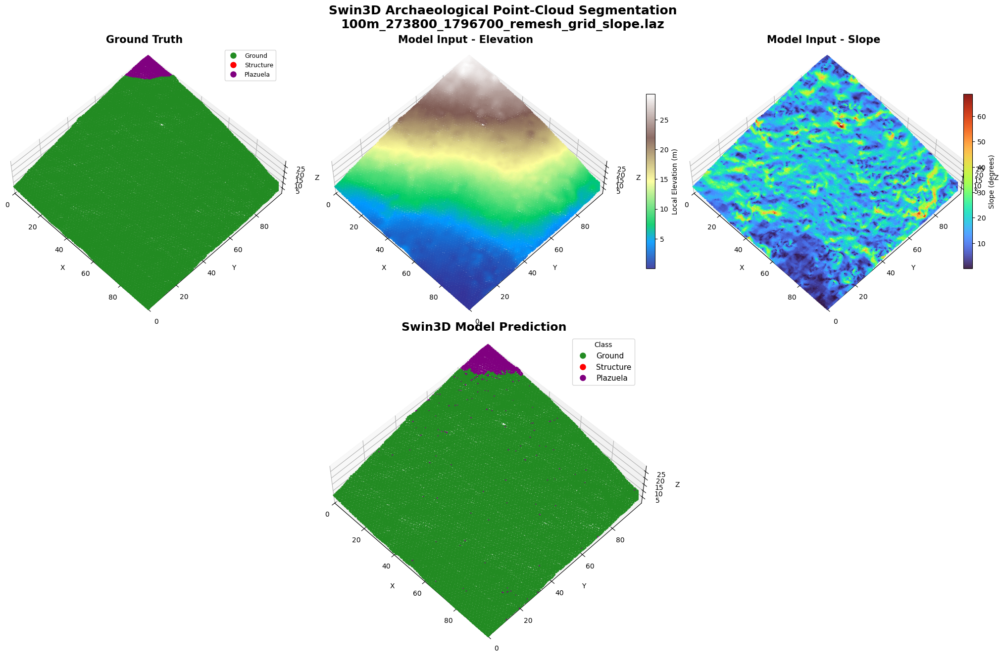


Tile: tile_redacted_0086.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,717
  Structure :          0
  Plazuela  :      1,283

Prediction counts:
  Ground    :     63,283
  Structure :          0
  Plazuela  :      1,717

Point accuracy: 0.9930

Highest Accuracy Tile #2
Tile index: 7
Accuracy: 0.9880


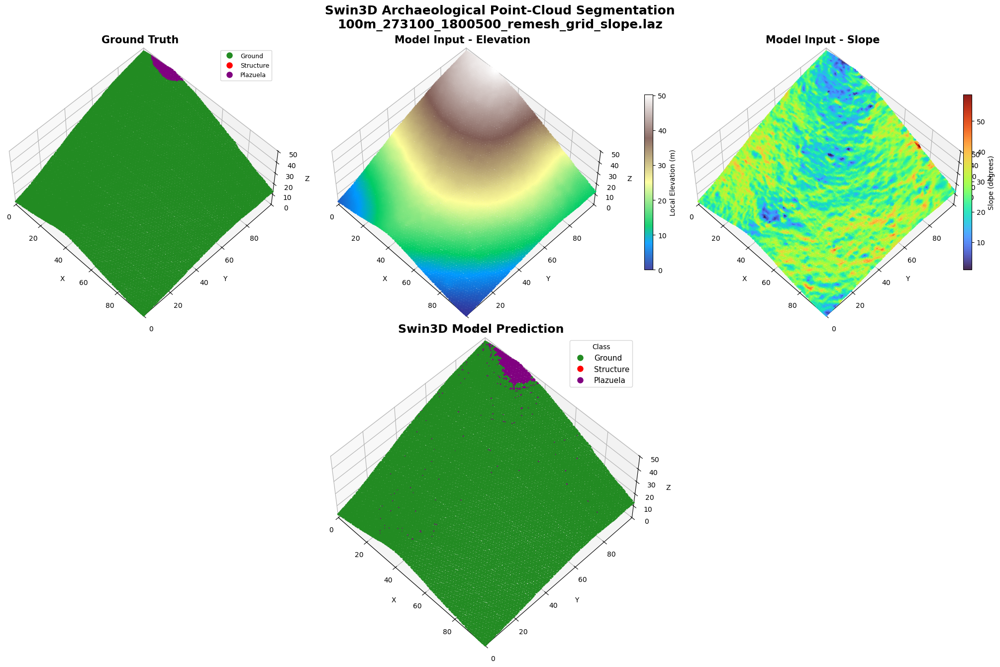


Tile: tile_redacted_0034.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     64,324
  Structure :          0
  Plazuela  :        676

Prediction counts:
  Ground    :     63,740
  Structure :          0
  Plazuela  :      1,260

Point accuracy: 0.9900

Highest Accuracy Tile #3
Tile index: 36
Accuracy: 0.9867


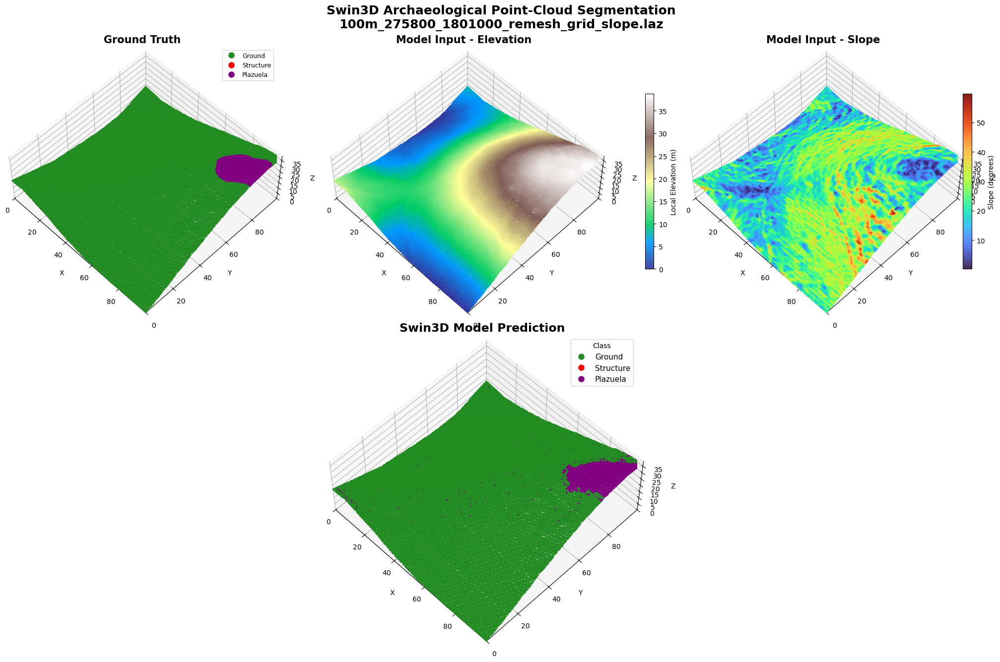


Tile: tile_redacted_0056.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     62,365
  Structure :          0
  Plazuela  :      2,635

Prediction counts:
  Ground    :     61,914
  Structure :          0
  Plazuela  :      3,086

Point accuracy: 0.9860

Highest Accuracy Tile #4
Tile index: 64
Accuracy: 0.9854


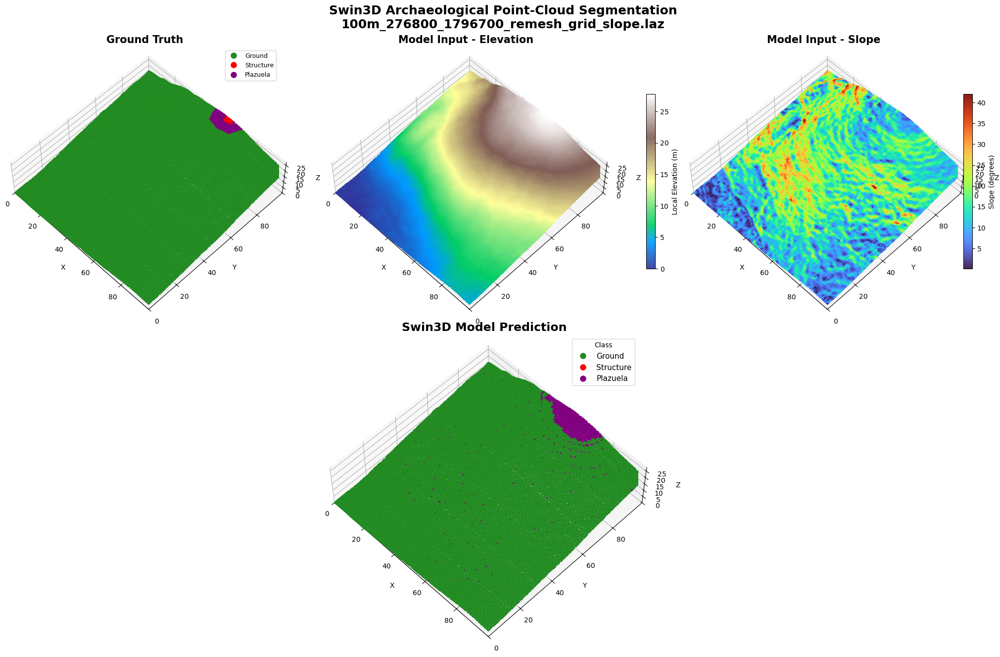


Tile: tile_redacted_0078.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     64,136
  Structure :         98
  Plazuela  :        766

Prediction counts:
  Ground    :     63,055
  Structure :          0
  Plazuela  :      1,945

Point accuracy: 0.9819

Highest Accuracy Tile #5
Tile index: 40
Accuracy: 0.9849


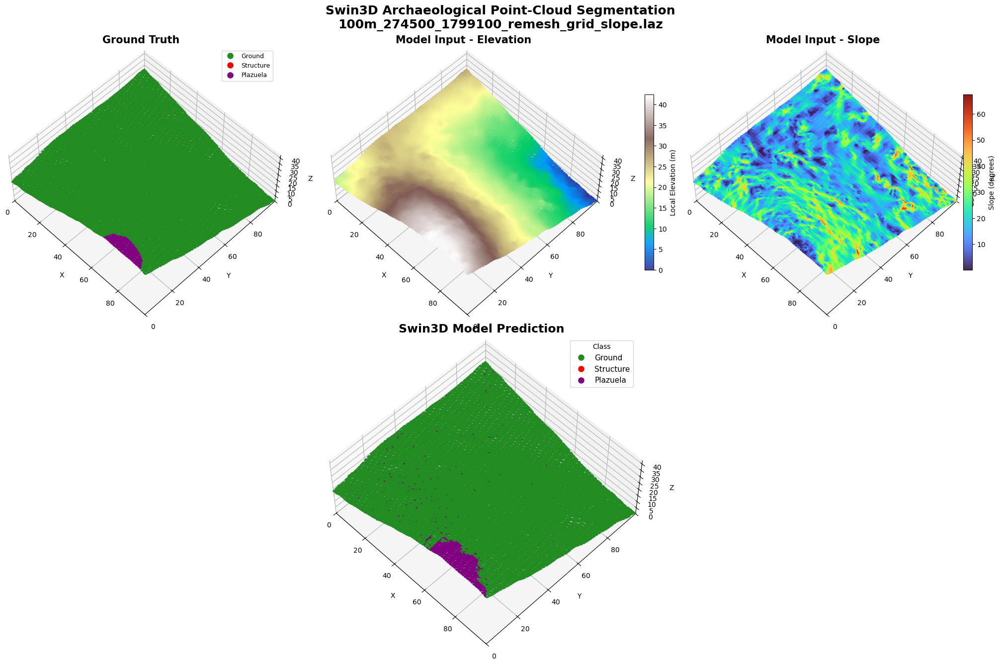


Tile: tile_redacted_0060.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,968
  Structure :          0
  Plazuela  :      1,032

Prediction counts:
  Ground    :     63,042
  Structure :          0
  Plazuela  :      1,958

Point accuracy: 0.9837


In [16]:
best_accuracy_outputs = []

for rank, tile in enumerate(
    extreme_tiles[
        "highest_accuracy"
    ],
    start=1,
):

    best_accuracy_index = tile[
        "index"
    ]

    print()
    print("=" * 70)
    print(
        f"Highest Accuracy Tile #{rank}"
    )
    print(
        f"Tile index: {best_accuracy_index}"
    )
    print(
        f"Accuracy: {tile['accuracy']:.4f}"
    )
    print("=" * 70)

    output = visualize_tile(
        model=model,
        dataset=test_loader.dataset,
        tile_index=best_accuracy_index,
        device=device,

        max_plot_points=50_000,
        point_size=1.5,

        elevation_angle=55,
        azimuth_angle=-45,
    )

    best_accuracy_outputs.append(
        output
    )


Highest False-Positive Tile #1
Tile index: 42
False-positive count: 16,044
False-positive rate: 0.2595


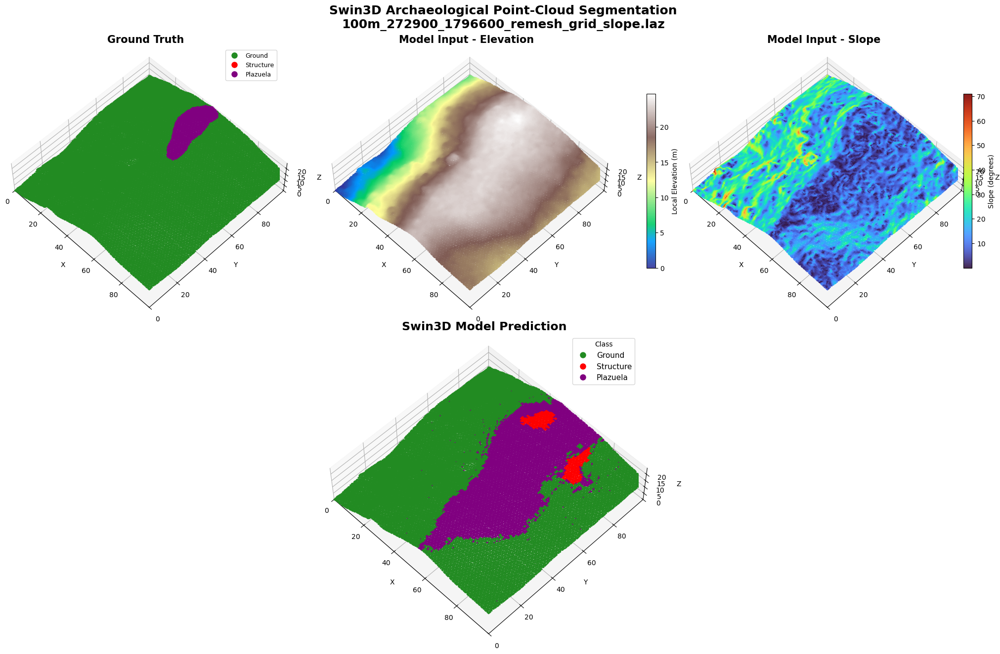


Tile: tile_redacted_0062.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     61,835
  Structure :          0
  Plazuela  :      3,165

Prediction counts:
  Ground    :     45,200
  Structure :      1,457
  Plazuela  :     18,343

Point accuracy: 0.7327

Highest False-Positive Tile #2
Tile index: 67
False-positive count: 9,718
False-positive rate: 0.1629


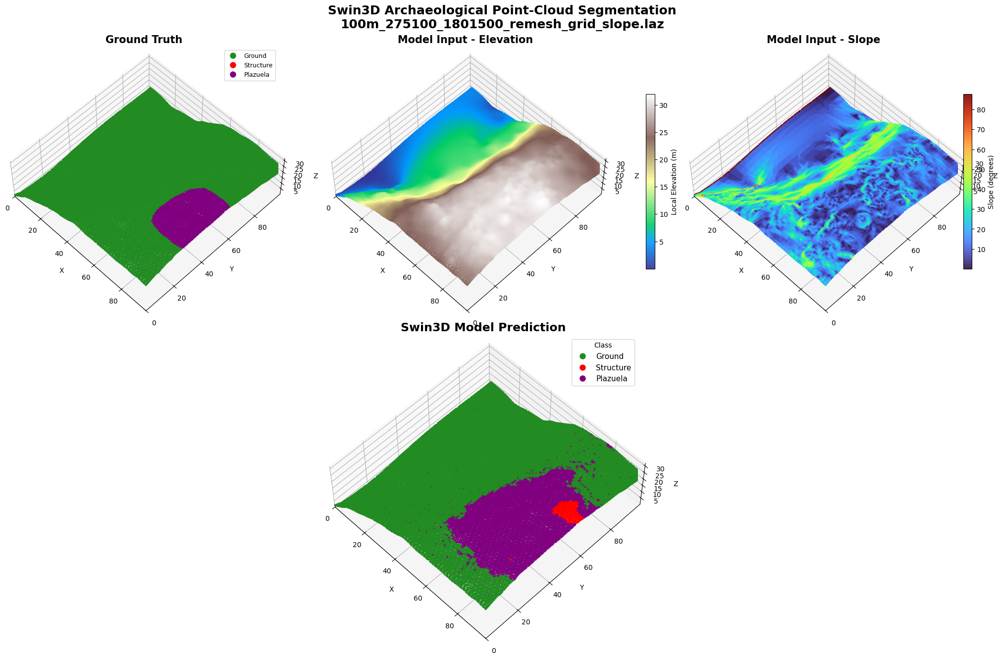


Tile: tile_redacted_0028.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     59,658
  Structure :          0
  Plazuela  :      5,342

Prediction counts:
  Ground    :     50,405
  Structure :        718
  Plazuela  :     13,877

Point accuracy: 0.8496

Highest False-Positive Tile #3
Tile index: 72
False-positive count: 9,415
False-positive rate: 0.1464


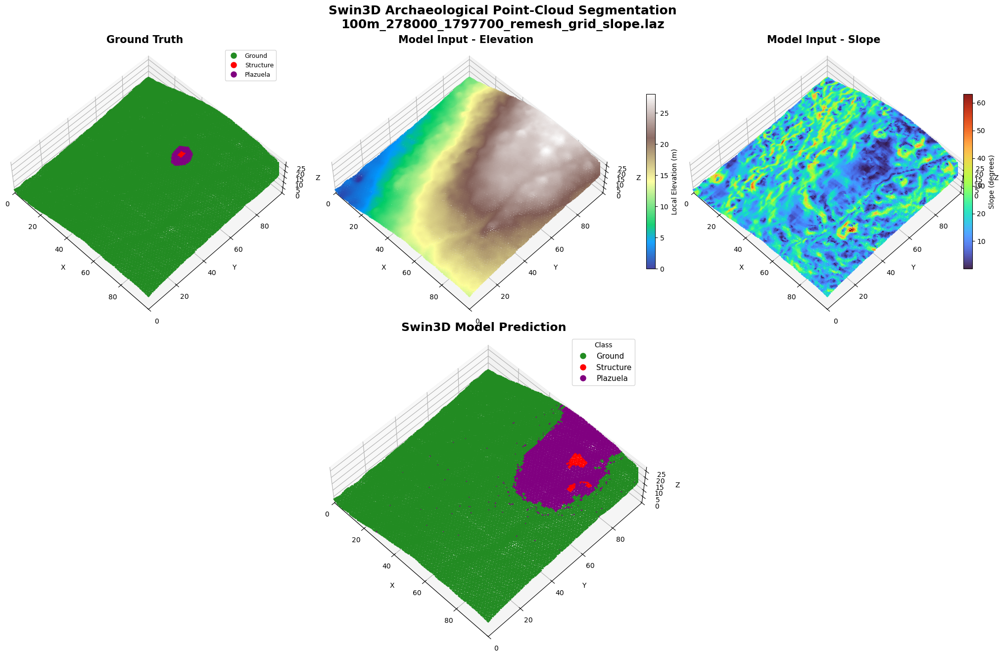


Tile: tile_redacted_0084.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     64,312
  Structure :         55
  Plazuela  :        633

Prediction counts:
  Ground    :     55,258
  Structure :        344
  Plazuela  :      9,398

Point accuracy: 0.8523

Highest False-Positive Tile #4
Tile index: 55
False-positive count: 7,772
False-positive rate: 0.1244


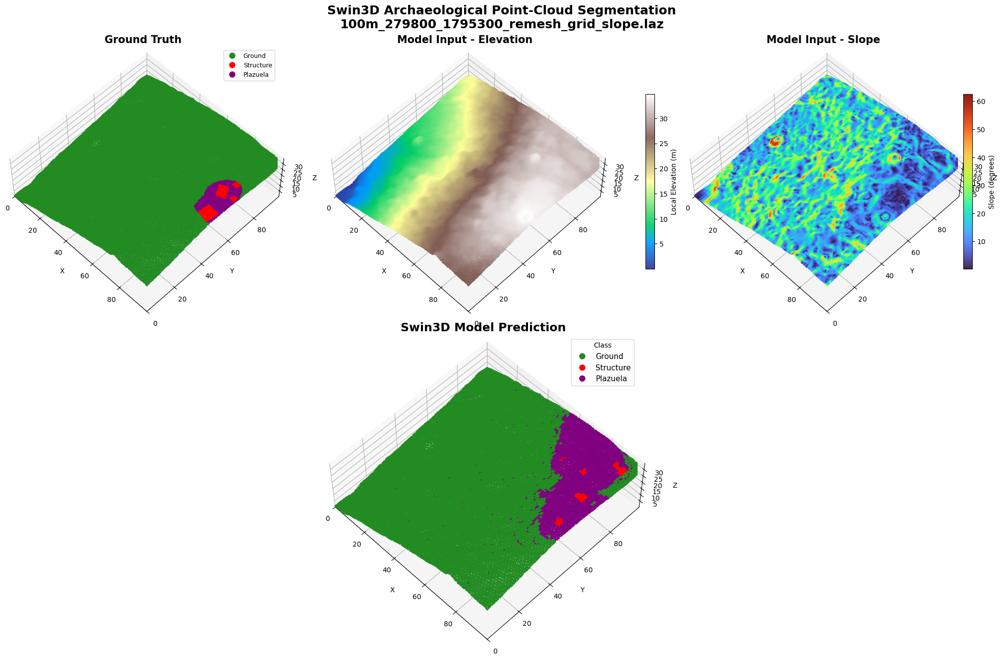


Tile: tile_redacted_0070.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     62,493
  Structure :        790
  Plazuela  :      1,717

Prediction counts:
  Ground    :     54,511
  Structure :        387
  Plazuela  :     10,102

Point accuracy: 0.8650

Highest False-Positive Tile #5
Tile index: 30
False-positive count: 7,366
False-positive rate: 0.1160


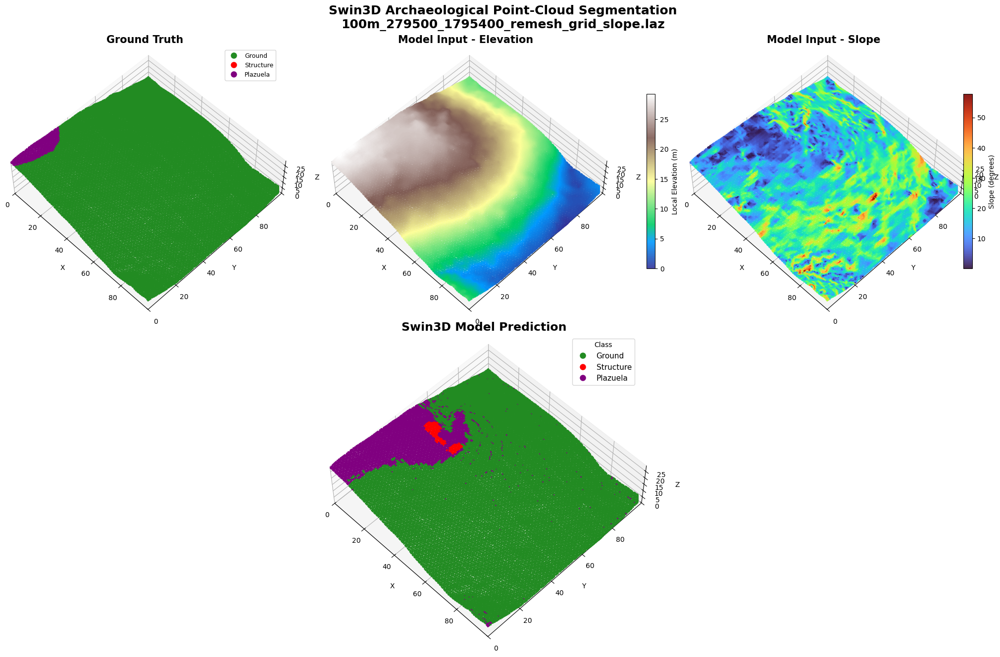


Tile: tile_redacted_0050.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,479
  Structure :          0
  Plazuela  :      1,521

Prediction counts:
  Ground    :     55,961
  Structure :        556
  Plazuela  :      8,483

Point accuracy: 0.8843


In [17]:
highest_fp_outputs = []

for rank, tile in enumerate(
    extreme_tiles[
        "highest_false_positive_count"
    ],
    start=1,
):

    highest_fp_index = tile[
        "index"
    ]

    print()
    print("=" * 70)
    print(
        f"Highest False-Positive Tile #{rank}"
    )
    print(
        f"Tile index: {highest_fp_index}"
    )
    print(
        f"False-positive count: "
        f"{tile['false_positive_count']:,}"
    )
    print(
        f"False-positive rate: "
        f"{tile['false_positive_rate']:.4f}"
    )
    print("=" * 70)

    output = visualize_tile(
        model=model,
        dataset=test_loader.dataset,
        tile_index=highest_fp_index,
        device=device,

        max_plot_points=50_000,
        point_size=1.5,

        elevation_angle=55,
        azimuth_angle=-45,
    )

    highest_fp_outputs.append(
        output
    )

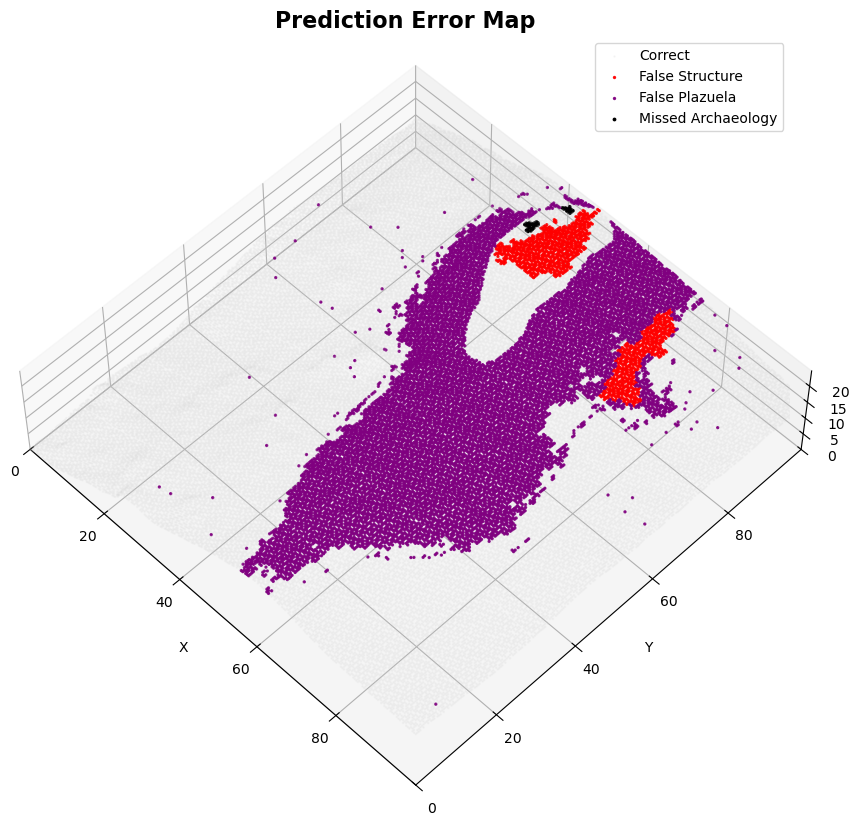

{'correct': 35975,
 'false_structure': 1242,
 'false_plazuela': 12746,
 'missed_archaeology': 37}

In [16]:
visualize_prediction_errors(
    highest_fp_output,

    max_plot_points=50_000,
    point_size=2.0,

    elevation_angle=55,
    azimuth_angle=-45,
)

In [17]:
from visualization.vis import (
    spatial_filter_predictions,
    compare_before_after_filter,
    visualize_filtered_prediction
)

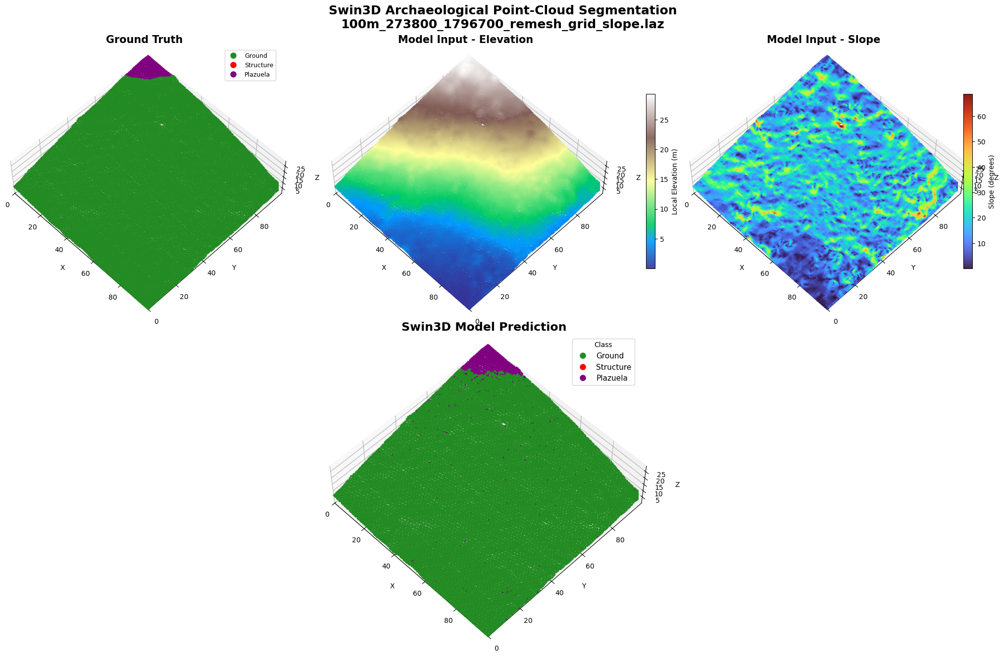


Tile: tile_redacted_0086.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,717
  Structure :          0
  Plazuela  :      1,283

Prediction counts:
  Ground    :     63,273
  Structure :          0
  Plazuela  :      1,727

Point accuracy: 0.9928


In [18]:
visualization_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=best_accuracy_index,
    device=device,

    max_plot_points=50_000,
    point_size=1.5,

    elevation_angle=55,
    azimuth_angle=-45,
)

In [19]:
filtered_predictions, filter_info = (
    spatial_filter_predictions(
        coords=visualization_output[
            "coords_np"
        ],

        predictions=visualization_output[
            "predictions_np"
        ],

        cell_size=1.0,

        structure_min_cells=8,
        plazuela_min_cells=15,

        opening_iterations=1,
        closing_iterations=0,

        verbose=True,
    )
)


Spatial filtering
-----------------

Structure
  Points before: 0
  Points after: 0
  Points removed: 0
  Components before: 0
  Components after: 0

Plazuela
  Points before: 1,727
  Points after: 1,498
  Points removed: 229
  Components before: 118
  Components after: 1


In [20]:
comparison = compare_before_after_filter(
    labels=visualization_output[
        "labels_np"
    ],

    original_predictions=(
        visualization_output[
            "predictions_np"
        ]
    ),

    filtered_predictions=(
        filtered_predictions
    ),
)


FILTER PERFORMANCE
Accuracy before: 0.9928
Accuracy after:  0.9962
Difference:      +0.0034

Ground
  Precision: 0.9998 -> 0.9997
  Recall:    0.9929 -> 0.9964
  FP:        11 -> 16

Structure
  Precision: 0.0000 -> 0.0000
  Recall:    0.0000 -> 0.0000
  FP:        0 -> 0

Plazuela
  Precision: 0.7365 -> 0.8458
  Recall:    0.9914 -> 0.9875
  FP:        455 -> 231



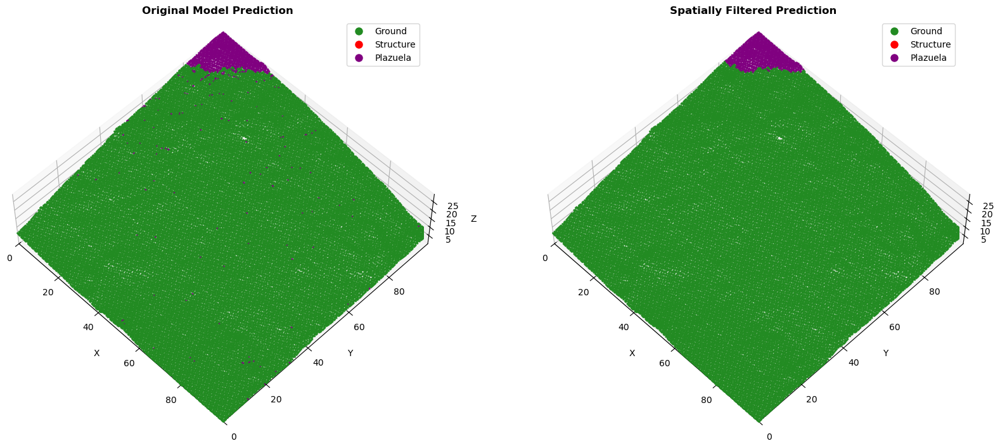


FILTER PERFORMANCE
Accuracy before: 0.9928
Accuracy after:  0.9962
Difference:      +0.0034

Ground
  Precision: 0.9998 -> 0.9997
  Recall:    0.9929 -> 0.9964
  FP:        11 -> 16

Structure
  Precision: 0.0000 -> 0.0000
  Recall:    0.0000 -> 0.0000
  FP:        0 -> 0

Plazuela
  Precision: 0.7365 -> 0.8458
  Recall:    0.9914 -> 0.9875
  FP:        455 -> 231



In [21]:
visualize_filtered_prediction(
    visualization_output=(
        visualization_output
    ),

    filtered_predictions=(
        filtered_predictions
    ),

    max_plot_points=50_000,
)